# Telco Customer Churn Analysis

## 1. Business Understanding

Pelanggan yang berhenti berlangganan dapat memengaruhi keberlanjutan pendapatan perusahaan. Analisis ini mengidentifikasi kelompok pelanggan tempat churn terkonsentrasi untuk membantu menentukan prioritas evaluasi retensi.

### Pertanyaan Bisnis
Di kelompok pelanggan mana churn terkonsentrasi, dan segmen mana yang perlu diprioritaskan untuk evaluasi retensi?

### Tujuan Analisis
- Mengukur jumlah pelanggan, jumlah churners, dan proporsi churn.
- Membandingkan proporsi churn dan kontribusi churn antarsegmen.
- Mengidentifikasi segmen prioritas dengan mempertimbangkan ukuran dan overlap.
- Menyusun rekomendasi serta metric evaluasi berdasarkan temuan.

Analisis menggunakan snapshot pelanggan. Hubungan antarvariabel digunakan untuk memahami pola, bukan membuktikan penyebab churn.

## 2. Data Preparation

Dataset tersedia dalam file `Telco_Churn_Data.zip`. Tahap awal meliputi upload, pemeriksaan isi ZIP, ekstraksi, dan pembacaan enam CSV.

In [1]:
import pandas as pd
import zipfile
from google.colab import files

pd.set_option("display.max_columns", None)

In [2]:
uploaded = files.upload()

Saving Telco_Churn_Data.zip to Telco_Churn_Data.zip


In [3]:
zip_name = "Telco_Churn_Data.zip"

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    for filename in zip_ref.namelist():
        print(filename)

Customer_Info.csv
Location_Data.csv
Online_Services.csv
Payment_Info.csv
Service_Options.csv
Status_Analysis.csv
TELCO ER Diagram.png
a_IBM Telco Customers Churn Datasets.xlsx


In [4]:
with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("data")

print("File berhasil diekstrak ke folder data.")

File berhasil diekstrak ke folder data.


In [5]:
customer_info = pd.read_csv("data/Customer_Info.csv")
service_options = pd.read_csv("data/Service_Options.csv")
online_services = pd.read_csv("data/Online_Services.csv")
payment_info = pd.read_csv("data/Payment_Info.csv")
status_analysis = pd.read_csv("data/Status_Analysis.csv")
location_data = pd.read_csv("data/Location_Data.csv")

print("Enam CSV berhasil dibaca.")

Enam CSV berhasil dibaca.


In [6]:
datasets = {
    "Customer Info": customer_info,
    "Service Options": service_options,
    "Online Services": online_services,
    "Payment Info": payment_info,
    "Status Analysis": status_analysis,
    "Location Data": location_data
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} baris × {df.shape[1]} kolom")

Customer Info: 7,043 baris × 9 kolom
Service Options: 7,043 baris × 10 kolom
Online Services: 7,043 baris × 11 kolom
Payment Info: 7,043 baris × 11 kolom
Status Analysis: 7,043 baris × 9 kolom
Location Data: 7,043 baris × 8 kolom


## 3. Data Understanding

Dataset terdiri dari enam tabel yang mencakup profil pelanggan, layanan, pembayaran, status churn, dan lokasi.

Tahap ini bertujuan memahami struktur tabel, grain, data types, dan target churn. Keunikan serta kesesuaian `customer_id` diperiksa sebelum merge.

In [7]:
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.head(3))


Customer Info


,customer_id,gender,age,under_30,senior_citizen,partner,dependents,number_of_dependents,married
0,0002-ORFBO,Female,37,No,No,Yes,No,0,Yes
1,0003-MKNFE,Male,46,No,No,No,No,0,No
2,0004-TLHLJ,Male,50,No,No,No,No,0,No



Service Options


,customer_id,tenure,internet_service,phone_service,multiple_lines,avg_monthly_gb_download,unlimited_data,offer,referred_a_friend,number_of_referrals
0,0002-ORFBO,9,Yes,Yes,No,16,Yes,NaN,Yes,2
1,0003-MKNFE,9,Yes,Yes,Yes,10,No,NaN,No,0
2,0004-TLHLJ,4,Yes,Yes,No,30,Yes,Offer E,No,0



Online Services


...

,customer_id,contract,paperless_billing,payment_method,monthly_ charges,avg_monthly_long_distance_charges,total_charges,total_refunds,total_extra_data_charges,total_long_distance_charges,total_revenue
0,0002-ORFBO,One Year,Yes,Mailed check,65.6,42.39,593.30,0.00,0,381.51,974.81
1,0003-MKNFE,Month-to-Month,No,Mailed check,59.9,10.69,542.40,38.33,10,96.21,610.28
2,0004-TLHLJ,Month-to-Month,Yes,Electronic check,73.9,33.65,280.85,0.00,0,134.60,415.45



Status Analysis


,customer_id,satisfaction_score,cltv,customer_status,churn_score,churn_label,churn_value,churn_category,churn_reason
0,0002-ORFBO,3,2205,Stayed,65,No,0,Not Applicable,NaN
1,0003-MKNFE,5,5414,Stayed,66,No,0,Not Applicable,NaN
2,0004-TLHLJ,1,4479,Churned,71,Yes,1,Competitor,Competitor had better devices



Location Data


,customer_id,country,state,city,zip_code,total_population,latitude,longitude
0,0002-ORFBO,United States,California,Frazier Park,93225,4498,34.827662,-118.999073
1,0003-MKNFE,United States,California,Glendale,91206,31297,34.162515,-118.203869
2,0004-TLHLJ,United States,California,Costa Mesa,92627,62069,33.645672,-117.922613


In [8]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    df.info()


--- Customer Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   customer_id           7043 non-null   object
 1   gender                7043 non-null   object
 2   age                   7043 non-null   int64 
 3   under_30              7043 non-null   object
 4   senior_citizen        7043 non-null   object
 5   partner               7043 non-null   object
 6   dependents            7043 non-null   object
 7   number_of_dependents  7043 non-null   int64 
 8   married               7043 non-null   object
dtypes: int64(2), object(7)
memory usage: 495.3+ KB

--- Service Options ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   customer_id              7

### 3.1 Dataset Overview

- **Customer Info:** profil pelanggan, seperti usia, gender, pasangan, dan tanggungan.
- **Service Options:** tenure, layanan utama, penggunaan data, offer, dan referral.
- **Online Services:** jenis internet dan layanan tambahan yang digunakan.
- **Payment Info:** contract, payment method, monthly charges, dan revenue yang tercatat.
- **Status Analysis:** customer status, indikator churn, satisfaction score, dan churn reason.
- **Location Data:** lokasi pelanggan dan informasi wilayah.

Seluruh tabel dihubungkan melalui `customer_id`. Grain yang diharapkan adalah satu baris per pelanggan pada setiap tabel.

In [9]:
reference_ids = set(customer_info["customer_id"])

for name, df in datasets.items():
    print(f"\n{name}")
    print(f"Rows: {len(df):,}")
    print(f"Unique customer IDs: {df['customer_id'].nunique():,}")
    print(f"Missing customer IDs: {df['customer_id'].isna().sum():,}")
    print(f"Duplicate customer IDs: {df['customer_id'].duplicated().sum():,}")
    print(
        "Same IDs as Customer Info:",
        set(df["customer_id"]) == reference_ids
    )


Customer Info
Rows: 7,043
Unique customer IDs: 7,043
Missing customer IDs: 0
Duplicate customer IDs: 0
Same IDs as Customer Info: True

Service Options
Rows: 7,043
Unique customer IDs: 7,043
Missing customer IDs: 0
Duplicate customer IDs: 0
Same IDs as Customer Info: True

Online Services
Rows: 7,043
Unique customer IDs: 7,043
Missing customer IDs: 0
Duplicate customer IDs: 0
Same IDs as Customer Info: True

Payment Info
Rows: 7,043
Unique customer IDs: 7,043
Missing customer IDs: 0
Duplicate customer IDs: 0
Same IDs as Customer Info: True

Status Analysis
Rows: 7,043
Unique customer IDs: 7,043
Missing customer IDs: 0
Duplicate customer IDs: 0
Same IDs as Customer Info: True

Location Data
Rows: 7,043
Unique customer IDs: 7,043
Missing customer IDs: 0
Duplicate customer IDs: 0
Same IDs as Customer Info: True


In [10]:
status_check = (
    status_analysis
    .groupby(
        ["customer_status", "churn_label", "churn_value"],
        dropna=False
    )
    .size()
    .reset_index(name="customers")
)

display(status_check)

,customer_status,churn_label,churn_value,customers
0,Churned,Yes,1,1869
1,Joined,No,0,454
2,Stayed,No,0,4720


In [11]:
total_customers = status_analysis["customer_id"].nunique()

churned_customers = status_analysis.loc[
    status_analysis["churn_value"] == 1,
    "customer_id"
].nunique()

churn_proportion = churned_customers / total_customers

print(f"Total customers: {total_customers:,}")
print(f"Churned customers: {churned_customers:,}")
print(f"Churn proportion: {churn_proportion:.2%}")

Total customers: 7,043
Churned customers: 1,869
Churn proportion: 26.54%


### 3.2 Initial Findings

Setiap tabel memiliki 7.043 unique customer IDs, tanpa missing maupun duplicate customer IDs. Keenam tabel mencakup pelanggan yang sama, sehingga hubungan antartabel bersifat one-to-one.

Customer status terdiri dari:
- Stayed: 4.720 pelanggan.
- Joined: 454 pelanggan.
- Churned: 1.869 pelanggan.

Kolom `churn_value` konsisten dengan customer status dan churn label. Nilai 1 menunjukkan Churned, sedangkan nilai 0 mencakup Stayed dan Joined.

Baseline churn proportion sebesar 26,54%, dihitung dari 1.869 churners dibagi 7.043 pelanggan. Pelanggan Joined termasuk dalam denominator, tetapi tetap dibedakan dari Stayed saat analisis profil pelanggan.

### 3.3 Data Notes and Limitations

- Churn proportion menggambarkan status pada snapshot dataset. Angka ini belum dapat disebut monthly atau annual churn rate tanpa memastikan periode dan definisinya.
- Analisis berdasarkan tenure membandingkan kelompok lama berlangganan, bukan menunjukkan calendar trend.
- Churn reason digunakan untuk memahami alasan yang tercatat pada pelanggan yang sudah churn.
- Kolom `monthly_ charges` memiliki spasi pada namanya dan perlu dirapikan saat cleaning.
- Kolom `phone_service` dan `internet_service` muncul pada dua tabel. Konsistensi nilainya perlu diperiksa sebelum merge.

## 4. Data Quality Assessment

Pemeriksaan mencakup missing values, duplicate rows, konsistensi antarkolom, dan outlier.

Temuan pada tahap ini digunakan sebagai dasar keputusan cleaning. Nilai kosong maupun nilai ekstrem tidak otomatis dianggap sebagai kesalahan.

In [12]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print(f"Duplicate rows: {df.duplicated().sum():,}")

    missing_summary = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100
    })

    display(
        missing_summary[missing_summary["missing_count"] > 0]
        .round(2)
    )

    text_columns = df.select_dtypes(include="object")
    blank_counts = text_columns.apply(
        lambda column: column.str.strip().eq("").sum()
    )

    print("Blank strings:")
    print(blank_counts[blank_counts > 0].to_dict())


--- Customer Info ---
Duplicate rows: 0


,missing_count,missing_pct


Blank strings:
{}

--- Service Options ---
Duplicate rows: 0


,missing_count,missing_pct
offer,3877,55.05


Blank strings:
{}

--- Online Services ---
Duplicate rows: 0


...

Blank strings:
{}

--- Status Analysis ---
Duplicate rows: 0


,missing_count,missing_pct
churn_reason,5174,73.46


Blank strings:
{}

--- Location Data ---
Duplicate rows: 0


,missing_count,missing_pct


Blank strings:
{}


In [13]:
raw_service = pd.read_csv(
    "data/Service_Options.csv",
    keep_default_na=False
)

raw_online = pd.read_csv(
    "data/Online_Services.csv",
    keep_default_na=False
)

print("Original offer values:")
display(raw_service["offer"].value_counts(dropna=False))

print("Original internet_type values:")
display(raw_online["internet_type"].value_counts(dropna=False))

print("Missing internet_type by internet_service:")
display(pd.crosstab(
    online_services["internet_service"],
    online_services["internet_type"].isna(),
    colnames=["internet_type_missing"]
))

print("Missing churn_reason by customer_status:")
display(pd.crosstab(
    status_analysis["customer_status"],
    status_analysis["churn_reason"].isna(),
    colnames=["churn_reason_missing"]
))

Original offer values:


,count
offer,
None,3877
Offer B,824
Offer E,805
Offer D,602
Offer A,520
Offer C,415


Original internet_type values:


,count
internet_type,
Fiber Optic,3035
DSL,1652
None,1526
Cable,830


Missing internet_type by internet_service:


internet_type_missing,False,True
internet_service,,
No,0,1526
Yes,5517,0


Missing churn_reason by customer_status:


churn_reason_missing,False,True
customer_status,,
Churned,1869,0
Joined,0,454
Stayed,0,4720


In [14]:
service_check = service_options[
    ["customer_id", "phone_service", "internet_service"]
].merge(
    online_services[
        ["customer_id", "phone_service", "internet_service"]
    ],
    on="customer_id",
    suffixes=("_options", "_online"),
    validate="one_to_one"
)

for column in ["phone_service", "internet_service"]:
    mismatches = (
        service_check[f"{column}_options"]
        != service_check[f"{column}_online"]
    ).sum()

    print(f"{column} mismatches: {mismatches:,}")

print(
    "Partner vs married mismatches:",
    (customer_info["partner"] != customer_info["married"]).sum()
)

print(
    "Churn status vs churn_value mismatches:",
    (
        status_analysis["customer_status"].eq("Churned")
        != status_analysis["churn_value"].eq(1)
    ).sum()
)

print(
    "Churn label vs churn_value mismatches:",
    (
        status_analysis["churn_label"].eq("Yes")
        != status_analysis["churn_value"].eq(1)
    ).sum()
)

phone_service mismatches: 0
internet_service mismatches: 0
Partner vs married mismatches: 0
Churn status vs churn_value mismatches: 0
Churn label vs churn_value mismatches: 0


### 4.1 Numeric Values and Outliers

Rentang nilai numerik diperiksa untuk menemukan nilai yang perlu ditinjau lebih lanjut.

Metode IQR digunakan sebagai screening outlier, dengan batas bawah Q1 − 1,5 × IQR dan batas atas Q3 + 1,5 × IQR. Nilai di luar batas ini belum tentu salah.

Pada kolom seperti refunds dan extra data charges, banyak pelanggan dapat memiliki nilai nol. Karena itu, nilai nonzero bisa terdeteksi sebagai outlier meskipun masih masuk akal secara bisnis.

In [15]:
numeric_checks = {
    "age": customer_info["age"],
    "number_of_dependents": customer_info["number_of_dependents"],
    "tenure": service_options["tenure"],
    "number_of_referrals": service_options["number_of_referrals"],
    "avg_monthly_gb_download": service_options["avg_monthly_gb_download"],
    "monthly_charges": payment_info["monthly_ charges"],
    "total_charges": payment_info["total_charges"],
    "total_refunds": payment_info["total_refunds"],
    "total_extra_data_charges": payment_info["total_extra_data_charges"],
    "total_revenue": payment_info["total_revenue"]
}

outlier_results = []

for column, values in numeric_checks.items():
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    flagged = (values < lower_bound) | (values > upper_bound)

    outlier_results.append({
        "column": column,
        "min": values.min(),
        "median": values.median(),
        "max": values.max(),
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": flagged.sum(),
        "outlier_pct": flagged.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(2))

,column,min,median,max,lower_bound,upper_bound,outlier_count,outlier_pct
0,age,19.00,46.00,80.00,-10.00,102.00,0,0.00
1,number_of_dependents,0.00,0.00,9.00,0.00,0.00,1627,23.10
2,tenure,0.00,29.00,72.00,-60.00,124.00,0,0.00
3,number_of_referrals,0.00,0.00,11.00,-4.50,7.50,676,9.60
4,avg_monthly_gb_download,0.00,17.00,85.00,-33.00,63.00,362,5.14
5,monthly_charges,18.25,70.35,118.75,-46.02,171.38,0,0.00
6,total_charges,18.80,1394.55,8684.80,-4679.52,8866.28,0,0.00
7,total_refunds,0.00,0.00,49.79,0.00,0.00,525,7.45
8,total_extra_data_charges,0.00,0.00,150.00,0.00,0.00,728,10.34
9,total_revenue,21.36,2108.64,11979.34,-5687.69,11094.45,21,0.30


### 4.2 Data Quality Findings

Tidak ditemukan duplicate rows, missing customer IDs, maupun duplicate customer IDs pada enam tabel. Seluruh tabel memiliki kumpulan pelanggan yang sama.

Kolom `phone_service` dan `internet_service` konsisten antartabel. Kolom `partner` dan `married` memiliki nilai identik pada dataset ini. Indikator churn juga konsisten dengan customer status.

#### Missing Values

- `offer`: 3.877 nilai berasal dari teks "None" pada CSV, yang dibaca pandas sebagai NaN. Nilai ini akan diberi label "No Offer".
- `internet_type`: 1.526 nilai berasal dari teks "None". Seluruhnya memiliki `internet_service = No`, sehingga akan diberi label "No Internet".
- `churn_reason`: 5.174 nilai kosong hanya terdapat pada pelanggan Stayed dan Joined, sehingga akan diberi label "Not Applicable".

Penanganan tersebut memperjelas kategori tanpa mengestimasi nilai numerik atau menghapus pelanggan.

#### Outliers

IQR menandai nilai pada number of dependents, referrals, penggunaan data, refunds, extra data charges, dan total revenue.

Pada number of dependents, refunds, dan extra data charges, Q1 dan Q3 bernilai nol. Akibatnya, seluruh nilai positif ditandai sebagai outlier.

Belum ada bukti dari screening ini yang mengharuskan penghapusan nilai ekstrem. Seluruh baris dipertahankan untuk pemeriksaan konsistensi berikutnya.

Nilai `tenure = 0` tetap perlu ditinjau bersama informasi pembayaran meskipun tidak terdeteksi sebagai outlier IQR.

## 5. Data Integration and Cleaning

Enam tabel digabungkan menggunakan `customer_id` dengan hubungan one-to-one. Customer Info digunakan sebagai tabel utama.

Kolom layanan yang berulang dipertahankan dari Service Options karena nilainya sudah terbukti konsisten dengan Online Services.

Cleaning mencakup perapian nama kolom, pelabelan kategori yang terbaca sebagai missing, penyesuaian tipe ZIP code, dan penandaan tenure yang perlu diverifikasi.

In [16]:
online_for_merge = online_services.drop(
    columns=["phone_service", "internet_service"]
)

df_merged = customer_info.copy()

for table in [
    service_options,
    online_for_merge,
    payment_info,
    status_analysis,
    location_data
]:
    df_merged = df_merged.merge(
        table,
        on="customer_id",
        how="left",
        validate="one_to_one"
    )

df_merged = df_merged.rename(
    columns={"monthly_ charges": "monthly_charges"}
)

assert len(df_merged) == len(customer_info)
assert df_merged["customer_id"].is_unique
assert set(df_merged["customer_id"]) == set(customer_info["customer_id"])

print(f"Merged dataset: {df_merged.shape[0]:,} rows × {df_merged.shape[1]} columns")

Merged dataset: 7,043 rows × 51 columns


In [17]:
calculated_revenue = (
    df_merged["total_charges"]
    - df_merged["total_refunds"]
    + df_merged["total_extra_data_charges"]
    + df_merged["total_long_distance_charges"]
)

consistency_checks = {
    "Under 30 vs age": (
        df_merged["under_30"].eq("Yes")
        != df_merged["age"].lt(30)
    ).sum(),

    "Senior citizen vs age": (
        df_merged["senior_citizen"].eq("Yes")
        != df_merged["age"].ge(65)
    ).sum(),

    "Dependents vs number of dependents": (
        df_merged["dependents"].eq("Yes")
        != df_merged["number_of_dependents"].gt(0)
    ).sum(),

    "Revenue components vs total revenue": (
        calculated_revenue - df_merged["total_revenue"]
    ).abs().gt(0.01).sum()
}

for check, count in consistency_checks.items():
    print(f"{check}: {count:,} mismatches")

Under 30 vs age: 0 mismatches
Senior citizen vs age: 0 mismatches
Dependents vs number of dependents: 0 mismatches
Revenue components vs total revenue: 0 mismatches


In [18]:
zero_tenure = df_merged.loc[
    df_merged["tenure"].eq(0),
    [
        "customer_id",
        "tenure",
        "customer_status",
        "monthly_charges",
        "total_charges"
    ]
].copy()

zero_tenure["charges_ratio"] = (
    zero_tenure["total_charges"]
    / zero_tenure["monthly_charges"]
)

print(f"Customers with zero tenure: {len(zero_tenure):,}")
display(zero_tenure.round(2))

Customers with zero tenure: 11


,customer_id,tenure,customer_status,monthly_charges,total_charges,charges_ratio
945,1371-DWPAZ,0,Stayed,56.05,560.50,10.00
1731,2520-SGTTA,0,Stayed,20.00,200.00,10.00
1906,2775-SEFEE,0,Stayed,61.90,619.00,10.00
2025,2923-ARZLG,0,Stayed,19.70,197.54,10.03
2176,3115-CZMZD,0,Stayed,20.25,202.50,10.00
2250,3213-VVOLG,0,Stayed,25.35,253.50,10.00
2855,4075-WKNIU,0,Stayed,73.35,733.50,10.00
3052,4367-NUYAO,0,Stayed,25.75,257.50,10.00
3118,4472-LVYGI,0,Stayed,52.55,525.50,10.00
4054,5709-LVOEQ,0,Stayed,80.85,808.50,10.00


### 5.1 Cleaning Decisions

#### Penanganan Nilai Kosong

Nilai kosong ditangani sesuai kondisi pelanggan, karena tidak semuanya berarti data hilang:

- `offer`: diisi **"No Offer"** untuk menunjukkan pelanggan tidak memiliki penawaran.
- `internet_type`: diisi **"No Internet"** jika pelanggan tidak menggunakan layanan internet.
- `churn_reason`: diisi **"Not Applicable"** untuk pelanggan yang tidak berstatus Churned, karena alasan berhenti tidak berlaku bagi mereka.

#### Pemeriksaan Tenure 0

Tenure adalah lama pelanggan berlangganan dalam bulan.

Sebanyak 11 pelanggan tercatat memiliki tenure 0, tetapi sudah memiliki total tagihan positif dan berstatus Stayed. Kondisi ini perlu diperiksa karena lama berlangganan dan riwayat tagihannya terlihat tidak sesuai.

Total tagihan mereka sekitar 10 kali tagihan bulanan saat ini. Namun, hal ini belum membuktikan bahwa mereka sudah berlangganan selama 10 bulan, karena besarnya tagihan dapat berubah dari waktu ke waktu.

Karena belum ada dasar yang cukup untuk memperbaikinya:

- Nilai tenure tetap dipertahankan.
- Kolom `tenure_review_flag` ditambahkan sebagai penanda pelanggan yang perlu diperiksa.
- Dalam analisis kelompok tenure, pelanggan tersebut dimasukkan ke kelompok **"Needs Review"**, terpisah dari pelanggan dengan tenure 1–6 bulan.

#### Penanganan Outlier

Metode IQR digunakan untuk menandai nilai yang jauh dari sebagian besar data. Nilai yang ditandai tidak otomatis dianggap salah.

Karena belum ditemukan bukti bahwa nilai tersebut merupakan kesalahan pencatatan, nilainya tetap dipertahankan. Tidak ada baris yang dihapus atau nilai yang dibatasi hanya karena terdeteksi sebagai outlier.

#### Penyesuaian Tipe Data dan Kolom

- `zip_code` disimpan sebagai teks karena digunakan sebagai kode wilayah, bukan untuk perhitungan.
- Kolom `married` dihapus karena isinya sama dengan `partner` pada seluruh pelanggan. Informasi tersebut tetap tersedia dalam kolom `partner`.

In [19]:
df_clean = df_merged.copy()

df_clean["offer"] = df_clean["offer"].fillna("No Offer")

df_clean.loc[
    df_clean["internet_type"].isna()
    & df_clean["internet_service"].eq("No"),
    "internet_type"
] = "No Internet"

df_clean.loc[
    df_clean["churn_reason"].isna()
    & df_clean["customer_status"].isin(["Stayed", "Joined"]),
    "churn_reason"
] = "Not Applicable"

df_clean["zip_code"] = df_clean["zip_code"].astype("string")

df_clean["tenure_review_flag"] = df_clean["tenure"].eq(0)

df_clean = df_clean.drop(columns="married")

print("Cleaning completed.")

Cleaning completed.


In [20]:
assert len(df_clean) == len(df_merged)
assert df_clean["customer_id"].is_unique
assert df_clean["customer_id"].notna().all()
assert df_clean["churn_value"].equals(df_merged["churn_value"])
assert df_clean["tenure"].equals(df_merged["tenure"])
assert df_clean["churn_value"].isin([0, 1]).all()

remaining_missing = df_clean.isna().sum()

print(f"Total customers: {len(df_clean):,}")
print(f"Churned customers: {df_clean['churn_value'].sum():,}")
print(f"Churn proportion: {df_clean['churn_value'].mean():.2%}")
print(f"Tenure flagged for review: {df_clean['tenure_review_flag'].sum():,}")
print(f"Remaining missing values: {remaining_missing.sum():,}")

display(remaining_missing[remaining_missing > 0])

Total customers: 7,043
Churned customers: 1,869
Churn proportion: 26.54%
Tenure flagged for review: 11
Remaining missing values: 0


,0


### 5.2 Cleaning Summary

Dataset tetap mencakup 7.043 pelanggan dan 1.869 churners, dengan churn proportion 26,54%. Tidak ada pelanggan yang dihapus.

Structural missing values telah diberi label sesuai konteksnya. Kolom layanan berulang ditangani saat merge, nama monthly charges dirapikan, dan ZIP code diubah menjadi teks.

Sebanyak 11 pelanggan diberi tenure review flag tanpa mengubah nilai tenure asli. Kolom ini menjadi catatan kualitas data, bukan indikator risiko churn.

## 6. Feature Engineering

Kolom tambahan dibuat untuk memudahkan segmentasi dan penggunaan filter pada dashboard.

- `churn_flag`: indikator 1 untuk Churned dan 0 untuk Stayed atau Joined.
- `tenure_group`: kelompok lama berlangganan.
- `tenure_group_order`: urutan kelompok tenure pada visual.
- `is_monthly_contract`: penanda pelanggan dengan kontrak bulanan.
- `is_fiber_optic`: penanda pelanggan pengguna Fiber Optic.

Pelanggan dengan tenure 0 ditempatkan pada kelompok "Needs Review". Kelompok ini tetap masuk total pelanggan, tetapi tidak digabungkan dengan tenure 1–6 bulan.

Kelompok tenure merupakan pembagian untuk analisis, bukan batas risiko yang sudah terbukti.

In [21]:
df_analysis = df_clean.copy()

df_analysis["churn_flag"] = df_analysis["churn_value"].astype(int)

df_analysis["tenure_group"] = pd.cut(
    df_analysis["tenure"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=[
        "1–6 months",
        "7–12 months",
        "13–24 months",
        "25–48 months",
        "49–72 months"
    ]
)

df_analysis["tenure_group"] = (
    df_analysis["tenure_group"]
    .cat.add_categories(["Needs Review"])
)

df_analysis.loc[
    df_analysis["tenure_review_flag"],
    "tenure_group"
] = "Needs Review"

tenure_order = {
    "1–6 months": 1,
    "7–12 months": 2,
    "13–24 months": 3,
    "25–48 months": 4,
    "49–72 months": 5,
    "Needs Review": 6
}

df_analysis["tenure_group_order"] = (
    df_analysis["tenure_group"]
    .astype("string")
    .map(tenure_order)
)

df_analysis["is_monthly_contract"] = (
    df_analysis["contract"].eq("Month-to-Month")
)

df_analysis["is_fiber_optic"] = (
    df_analysis["internet_type"].eq("Fiber Optic")
)

In [22]:
assert len(df_analysis) == len(df_clean)
assert df_analysis["customer_id"].is_unique
assert df_analysis["tenure_group"].notna().all()
assert df_analysis["tenure_group_order"].notna().all()
assert df_analysis["churn_flag"].equals(df_analysis["churn_value"])

assert (
    df_analysis["tenure_group"].eq("Needs Review")
    == df_analysis["tenure_review_flag"]
).all()

tenure_counts = (
    df_analysis
    .groupby(
        ["tenure_group", "tenure_group_order"],
        observed=True
    )
    .size()
    .reset_index(name="customers")
    .sort_values("tenure_group_order")
)

display(tenure_counts)
print(f"Total customers accounted for: {tenure_counts['customers'].sum():,}")

,tenure_group,tenure_group_order,customers
0,1–6 months,1,1470
1,7–12 months,2,705
2,13–24 months,3,1024
3,25–48 months,4,1594
4,49–72 months,5,2239
5,Needs Review,6,11


Total customers accounted for: 7,043


## 7. Data Export

Dua file disiapkan:

- `telco_churn_cleaned.csv`: hasil merge dan cleaning, termasuk tenure review flag.
- `telco_churn_powerbi.csv`: data customer-level dengan kolom tambahan untuk analisis dan dashboard.

Keduanya memiliki satu baris per pelanggan. Kolom ZIP code perlu diatur sebagai Text saat diimpor ke Power BI karena CSV tidak menyimpan metadata tipe data.

In [23]:
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

df_clean.to_csv(
    output_dir / "telco_churn_cleaned.csv",
    index=False
)

df_analysis.to_csv(
    output_dir / "telco_churn_powerbi.csv",
    index=False
)

with zipfile.ZipFile(
    "Telco_Churn_Prepared_Data.zip",
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_ref:
    for filename in [
        "telco_churn_cleaned.csv",
        "telco_churn_powerbi.csv"
    ]:
        zip_ref.write(
            output_dir / filename,
            arcname=filename
        )

files.download("Telco_Churn_Prepared_Data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Exploratory Data Analysis

### 8.1 Metric Definitions

Analisis menggunakan tiga ukuran utama:

- **Customers:** jumlah pelanggan dalam kelompok.
- **Churn rate:** jumlah churners dibagi jumlah pelanggan dalam kelompok.
- **Share of all churners:** jumlah churners dalam kelompok dibagi seluruh churners dalam dataset.

Istilah churn rate pada analisis ini merujuk pada proporsi churn dalam snapshot, bukan monthly atau annual churn rate.

Churn rate menunjukkan seberapa besar proporsi churn dalam kelompok. Share of all churners menunjukkan kontribusi kelompok terhadap keseluruhan masalah.

Keduanya dibaca bersama ukuran kelompok agar prioritas tidak hanya didasarkan pada persentase yang tinggi.

In [24]:
status_summary = (
    df_analysis
    .groupby("customer_status")
    .agg(customers=("customer_id", "size"))
    .reindex(["Stayed", "Joined", "Churned"])
)

status_summary["customer_share_pct"] = (
    status_summary["customers"] / len(df_analysis) * 100
)

display(status_summary.round(2))

print(f"Total customers: {len(df_analysis):,}")
print(f"Total churners: {df_analysis['churn_flag'].sum():,}")
print(f"Overall churn rate: {df_analysis['churn_flag'].mean():.2%}")

,customers,customer_share_pct
customer_status,,
Stayed,4720,67.02
Joined,454,6.45
Churned,1869,26.54


Total customers: 7,043
Total churners: 1,869
Overall churn rate: 26.54%


In [25]:
total_churners = df_analysis["churn_flag"].sum()

contract_summary = (
    df_analysis
    .groupby("contract")
    .agg(
        customers=("customer_id", "size"),
        churners=("churn_flag", "sum")
    )
    .reindex(["Month-to-Month", "One Year", "Two Year"])
)

contract_summary["customer_share_pct"] = (
    contract_summary["customers"] / len(df_analysis) * 100
)

contract_summary["churn_rate_pct"] = (
    contract_summary["churners"]
    / contract_summary["customers"] * 100
)

contract_summary["share_of_all_churners_pct"] = (
    contract_summary["churners"] / total_churners * 100
)

display(contract_summary.round(2))

assert contract_summary["customers"].sum() == len(df_analysis)
assert contract_summary["churners"].sum() == total_churners

,customers,churners,customer_share_pct,churn_rate_pct,share_of_all_churners_pct
contract,,,,,
Month-to-Month,3610,1655,51.26,45.84,88.55
One Year,1550,166,22.01,10.71,8.88
Two Year,1883,48,26.74,2.55,2.57


### 8.2 Churn Concentration by Contract

Sebanyak 1.869 dari 7.043 pelanggan berstatus Churned, sehingga baseline churn rate dalam snapshot adalah 26,54%.

Kontrak Month-to-Month mencakup 3.610 pelanggan atau 51,26% customer base, tetapi menyumbang 1.655 churners atau 88,55% seluruh churners.

Churn rate dalam kelompok Month-to-Month sebesar 45,84%, lebih tinggi daripada baseline keseluruhan.

Artinya, konsentrasi churn pada kontrak bulanan tidak hanya berkaitan dengan ukuran kelompoknya yang besar. Proporsi pelanggan yang churn dalam kelompok ini juga lebih tinggi.

Temuan ini menjadikan pelanggan Month-to-Month fokus pendalaman berikutnya, terutama berdasarkan tenure dan jenis internet. Hasil ini belum membuktikan bahwa perubahan kontrak akan menyebabkan penurunan churn.

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "font.size": 10
})

blue = "#2F5FD0"
orange = "#E58045"
grey = "#B8C2D1"

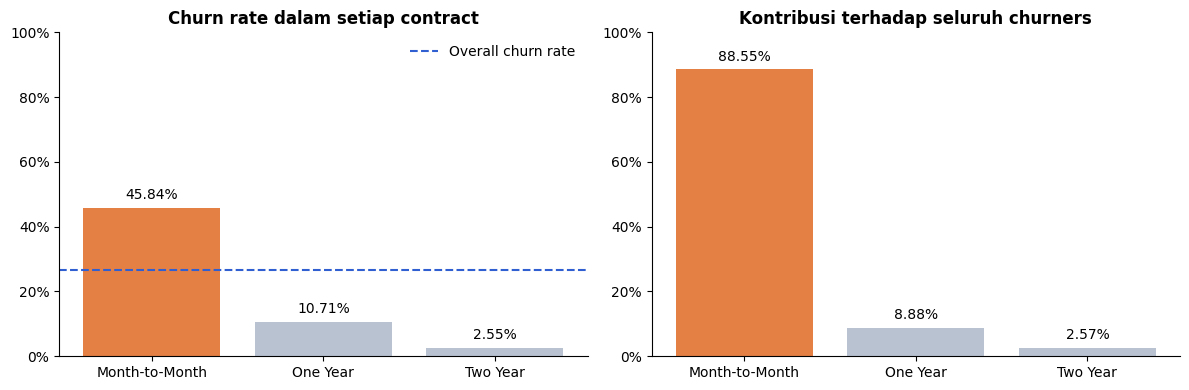

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

metrics = [
    ("churn_rate_pct", "Churn rate dalam setiap contract"),
    ("share_of_all_churners_pct", "Kontribusi terhadap seluruh churners")
]

for ax, (metric, title) in zip(axes, metrics):
    bars = ax.bar(
        contract_summary.index,
        contract_summary[metric],
        color=[orange, grey, grey]
    )

    ax.bar_label(bars, fmt="%.2f%%", padding=4)
    ax.set_title(title)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.set_xlabel("")

axes[0].axhline(
    df_analysis["churn_flag"].mean() * 100,
    color=blue,
    linestyle="--",
    label="Overall churn rate"
)
axes[0].legend(frameon=False)

plt.tight_layout()
plt.show()

### 8.3 Deep Dive: Month-to-Month Customers

Month-to-Month menjadi fokus pendalaman karena menyumbang 88,55% seluruh churners.

Analisis berikut membandingkan kelompok tenure dan jenis internet di dalam contract yang sama. Pendekatan ini membantu memperjelas pola tanpa mencampurkan perbedaan jenis contract.

Perbandingan ini tetap bersifat deskriptif. Karakteristik lain dalam setiap kelompok masih dapat berbeda.

In [28]:
def summarize_churn(data, group_column):
    summary = (
        data
        .groupby(group_column, observed=True)
        .agg(
            customers=("customer_id", "size"),
            churners=("churn_flag", "sum")
        )
    )

    summary["churn_rate_pct"] = (
        summary["churners"] / summary["customers"] * 100
    )

    summary["share_of_all_churners_pct"] = (
        summary["churners"]
        / df_analysis["churn_flag"].sum() * 100
    )

    return summary

In [29]:
monthly_customers = df_analysis.loc[
    df_analysis["is_monthly_contract"]
].copy()

monthly_tenure = summarize_churn(
    monthly_customers,
    "tenure_group"
)

monthly_tenure = monthly_tenure.reindex(
    list(tenure_order.keys())
).dropna(subset=["customers"])

display(monthly_tenure.round(2))

assert monthly_tenure["customers"].sum() == len(monthly_customers)
assert (
    monthly_tenure["churners"].sum()
    == monthly_customers["churn_flag"].sum()
)

,customers,churners,churn_rate_pct,share_of_all_churners_pct
tenure_group,,,,
1–6 months,1367.0,780.0,57.06,41.73
7–12 months,546.0,244.0,44.69,13.06
13–24 months,686.0,278.0,40.52,14.87
25–48 months,715.0,264.0,36.92,14.13
49–72 months,296.0,89.0,30.07,4.76


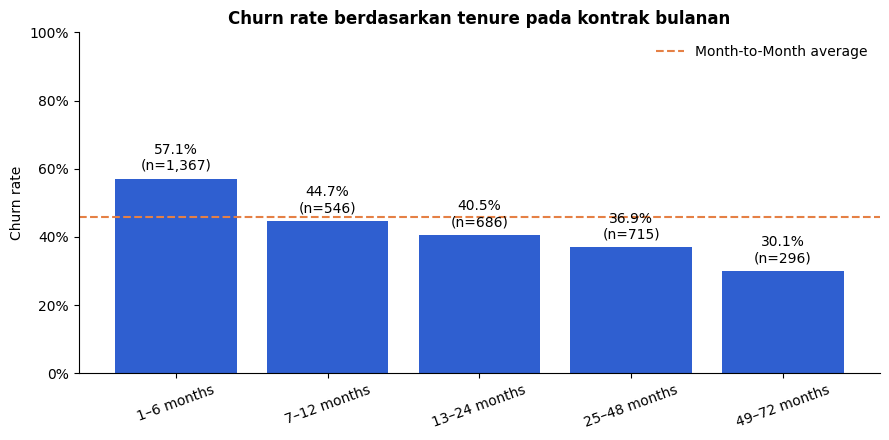

In [30]:
fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.bar(
    monthly_tenure.index.astype(str),
    monthly_tenure["churn_rate_pct"],
    color=blue
)

labels = [
    f"{rate:.1f}%\n(n={int(count):,})"
    for rate, count in zip(
        monthly_tenure["churn_rate_pct"],
        monthly_tenure["customers"]
    )
]

ax.bar_label(bars, labels=labels, padding=4)

ax.axhline(
    monthly_customers["churn_flag"].mean() * 100,
    color=orange,
    linestyle="--",
    label="Month-to-Month average"
)

ax.set_title("Churn rate berdasarkan tenure pada kontrak bulanan")
ax.set_ylabel("Churn rate")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.tick_params(axis="x", labelrotation=20)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

#### Insight: Short-Tenure Customers

Pada kontrak Month-to-Month, kelompok tenure 1–6 bulan mencakup 1.367 pelanggan dengan 780 churners.

Churn rate kelompok ini sebesar 57,06%, lebih tinggi daripada rata-rata kontrak bulanan sebesar 45,84%. Kelompok tersebut menyumbang 41,73% seluruh churners dalam dataset.

Temuan ini mendukung prioritas pemeriksaan pengalaman awal berlangganan pada pelanggan kontrak bulanan.

Angka 57,06% merupakan proporsi churn pada kelompok tenure dalam snapshot, bukan probabilitas pelanggan baru akan churn dalam enam bulan. Perhitungan tersebut memerlukan cohort dengan periode pengamatan yang setara.

,customers,churners,churn_rate_pct,share_of_all_churners_pct
internet_type,,,,
Fiber Optic,1882,1107,58.82,59.23
Cable,423,187,44.21,10.01
DSL,787,262,33.29,14.02
No Internet,518,99,19.11,5.30


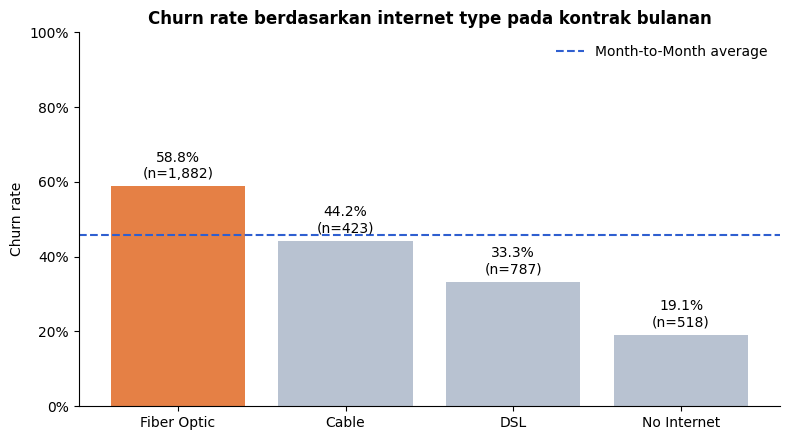

In [31]:
monthly_internet = summarize_churn(
    monthly_customers,
    "internet_type"
).sort_values("churn_rate_pct", ascending=False)

display(monthly_internet.round(2))

assert monthly_internet["customers"].sum() == len(monthly_customers)
assert (
    monthly_internet["churners"].sum()
    == monthly_customers["churn_flag"].sum()
)

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    monthly_internet.index,
    monthly_internet["churn_rate_pct"],
    color=[
        orange if category == "Fiber Optic" else grey
        for category in monthly_internet.index
    ]
)

labels = [
    f"{rate:.1f}%\n(n={int(count):,})"
    for rate, count in zip(
        monthly_internet["churn_rate_pct"],
        monthly_internet["customers"]
    )
]

ax.bar_label(bars, labels=labels, padding=4)

ax.axhline(
    monthly_customers["churn_flag"].mean() * 100,
    color=blue,
    linestyle="--",
    label="Month-to-Month average"
)

ax.set_title("Churn rate berdasarkan internet type pada kontrak bulanan")
ax.set_ylabel("Churn rate")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

#### Insight: Fiber Optic Customers

Pelanggan Month-to-Month dengan Fiber Optic berjumlah 1.882, termasuk 1.107 churners.

Churn rate kelompok ini sebesar 58,82%, lebih tinggi daripada rata-rata kontrak bulanan sebesar 45,84%. Kelompok tersebut menyumbang 59,23% seluruh churners.

Fiber Optic menjadi area pendalaman berikutnya, tetapi hasil ini belum membuktikan bahwa jenis internet menyebabkan churn. Tenure, biaya, layanan tambahan, dan pengalaman pelanggan masih perlu dipertimbangkan.

#### Segment Overlap

Kelompok Month-to-Month dengan tenure 1–6 bulan dan kelompok Month-to-Month dengan Fiber Optic dapat mencakup pelanggan yang sama.

Karena itu, kontribusi churn sebesar 41,73% dan 59,23% tidak boleh langsung dijumlahkan. Analisis berikutnya akan menghitung irisan dan gabungan pelanggan unik kedua segmen.

### 8.4 Segment Overlap and Prioritisation

Dua kelompok sebelumnya dapat mencakup pelanggan yang sama:
- Month-to-Month dengan tenure 1–6 bulan.
- Month-to-Month dengan Fiber Optic.

Analisis berikut menghitung irisan dan gabungan pelanggan unik, lalu membagi pelanggan kontrak bulanan menjadi kelompok yang tidak saling tumpang tindih.

Prioritas dipertimbangkan berdasarkan churn rate, jumlah churners, kontribusi churn, dan jumlah pelanggan yang masih aktif.

In [32]:
monthly_mask = df_analysis["is_monthly_contract"]
short_tenure_mask = df_analysis["tenure"].between(1, 6)
fiber_mask = df_analysis["is_fiber_optic"]

segment_a = monthly_mask & short_tenure_mask
segment_b = monthly_mask & fiber_mask

overlap_mask = segment_a & segment_b
union_mask = segment_a | segment_b

overlap_results = []

for name, mask in {
    "A: Monthly + tenure 1–6": segment_a,
    "B: Monthly + Fiber": segment_b,
    "Overlap A & B": overlap_mask,
    "Union A or B": union_mask
}.items():
    subset = df_analysis.loc[mask]

    overlap_results.append({
        "segment": name,
        "customers": len(subset),
        "churners": subset["churn_flag"].sum(),
        "churn_rate_pct": subset["churn_flag"].mean() * 100,
        "share_of_all_churners_pct": (
            subset["churn_flag"].sum() / total_churners * 100
        )
    })

display(pd.DataFrame(overlap_results).round(2))

assert union_mask.sum() == (
    segment_a.sum() + segment_b.sum() - overlap_mask.sum()
)

,segment,customers,churners,churn_rate_pct,share_of_all_churners_pct
0,A: Monthly + tenure 1–6,1367,780,57.06,41.73
1,B: Monthly + Fiber,1882,1107,58.82,59.23
2,Overlap A & B,573,444,77.49,23.76
3,Union A or B,2676,1443,53.92,77.21


In [33]:
df_analysis["monthly_segment"] = "Other contracts"

df_analysis.loc[monthly_mask, "monthly_segment"] = (
    "Other monthly customers"
)

df_analysis.loc[
    monthly_mask & short_tenure_mask & fiber_mask,
    "monthly_segment"
] = "Fiber | 1–6 months"

df_analysis.loc[
    monthly_mask & short_tenure_mask & ~fiber_mask,
    "monthly_segment"
] = "Non-Fiber | 1–6 months"

df_analysis.loc[
    monthly_mask & df_analysis["tenure"].gt(6) & fiber_mask,
    "monthly_segment"
] = "Fiber | >6 months"

# Jika ada tenure nol pada kontrak bulanan, pisahkan untuk review.
df_analysis.loc[
    monthly_mask & df_analysis["tenure_review_flag"],
    "monthly_segment"
] = "Monthly | tenure needs review"

segment_summary = summarize_churn(
    df_analysis.loc[monthly_mask],
    "monthly_segment"
).sort_values("churn_rate_pct", ascending=False)

display(segment_summary.round(2))

assert segment_summary["customers"].sum() == monthly_mask.sum()
assert (
    segment_summary["churners"].sum()
    == df_analysis.loc[monthly_mask, "churn_flag"].sum()
)

,customers,churners,churn_rate_pct,share_of_all_churners_pct
monthly_segment,,,,
Fiber | 1–6 months,573,444,77.49,23.76
Fiber | >6 months,1309,663,50.65,35.47
Non-Fiber | 1–6 months,794,336,42.32,17.98
Other monthly customers,934,212,22.70,11.34


#### Insight: Risiko Teramati dan Volume Churn Memberi Prioritas Berbeda

Irisan Month-to-Month, Fiber Optic, dan tenure 1–6 bulan mencakup 573 pelanggan dengan 444 churners. Churn rate sebesar 77,49%, dan kontribusinya mencapai 23,76% seluruh churners.

Namun, pelanggan Month-to-Month dengan Fiber Optic dan tenure lebih dari 6 bulan memiliki jumlah churners lebih besar: 663 pelanggan, atau 35,47% seluruh churners. Churn rate kelompok ini sebesar 50,65%.

Artinya, fokus hanya pada pelanggan dengan tenure pendek akan melewatkan bagian besar churn pada pelanggan Fiber yang sudah lebih lama berlangganan.

Gabungan dua segmen awal mencakup 2.676 pelanggan unik dan 1.443 churners, atau 77,21% seluruh churners. Perhitungan ini sudah menghindari double counting.

Hasil tersebut mendukung dua fokus evaluasi: pelanggan Fiber pada tahap awal berlangganan dan pelanggan Fiber dengan tenure lebih panjang. Bentuk tindakan masih perlu disesuaikan dengan alasan churn yang tercatat.

In [34]:
segment_status = pd.crosstab(
    df_analysis.loc[monthly_mask, "monthly_segment"],
    df_analysis.loc[monthly_mask, "customer_status"]
).reindex(
    columns=["Churned", "Stayed", "Joined"],
    fill_value=0
)

segment_status["active_customers"] = (
    segment_status["Stayed"] + segment_status["Joined"]
)

segment_profile = segment_summary.join(
    segment_status[["Stayed", "Joined", "active_customers"]]
)

display(segment_profile.round(2))

assert (
    segment_profile["churners"]
    + segment_profile["active_customers"]
    == segment_profile["customers"]
).all()

,customers,churners,churn_rate_pct,share_of_all_churners_pct,Stayed,Joined,active_customers
monthly_segment,,,,,,,
Fiber | 1–6 months,573,444,77.49,23.76,43,86,129
Fiber | >6 months,1309,663,50.65,35.47,646,0,646
Non-Fiber | 1–6 months,794,336,42.32,17.98,136,322,458
Other monthly customers,934,212,22.70,11.34,722,0,722


#### Active Customer Base

Kelompok Fiber dengan tenure 1–6 bulan memiliki 129 pelanggan yang belum churn: 43 Stayed dan 86 Joined.

Kelompok Fiber dengan tenure lebih dari 6 bulan memiliki 646 pelanggan Stayed. Kelompok ini memiliki lebih banyak churners sekaligus customer base aktif yang lebih besar untuk evaluasi retensi.

Secara keseluruhan, gabungan dua segmen awal mencakup 1.233 pelanggan aktif: 825 Stayed dan 408 Joined.

Pelanggan aktif tersebut memiliki karakteristik segmen yang sama dengan churners, tetapi belum tentu akan churn. Status Joined juga menunjukkan bahwa sebagian pelanggan memiliki waktu pengamatan yang pendek.

### 8.5 Churn Reasons by Segment

Churn category dan churn reason diperiksa hanya pada pelanggan berstatus Churned.

Persentase alasan dihitung terhadap jumlah churners di masing-masing segmen, bukan seluruh pelanggan segmen tersebut.

Alasan yang tercatat digunakan untuk mengarahkan pemeriksaan bisnis. Informasi ini belum membuktikan bahwa tindakan tertentu akan berhasil mempertahankan pelanggan.

In [35]:
monthly_churners = df_analysis.loc[
    monthly_mask & df_analysis["churn_flag"].eq(1)
].copy()

reason_counts = pd.crosstab(
    monthly_churners["monthly_segment"],
    monthly_churners["churn_category"]
)

reason_pct = reason_counts.div(
    reason_counts.sum(axis=1),
    axis=0
) * 100

print("Churners by category:")
display(reason_counts)

print("Percentage of churners within each segment:")
display(reason_pct.round(2))

assert reason_counts.to_numpy().sum() == len(monthly_churners)

Churners by category:


churn_category,Attitude,Competitor,Dissatisfaction,Other,Price
monthly_segment,,,,,
Fiber | 1–6 months,66,220,65,56,37
Fiber | >6 months,114,304,111,59,75
Non-Fiber | 1–6 months,64,134,58,29,51
Other monthly customers,40,90,33,30,19


Percentage of churners within each segment:


churn_category,Attitude,Competitor,Dissatisfaction,Other,Price
monthly_segment,,,,,
Fiber | 1–6 months,14.86,49.55,14.64,12.61,8.33
Fiber | >6 months,17.19,45.85,16.74,8.90,11.31
Non-Fiber | 1–6 months,19.05,39.88,17.26,8.63,15.18
Other monthly customers,18.87,42.45,15.57,14.15,8.96


In [36]:
reason_detail = (
    monthly_churners
    .groupby(["monthly_segment", "churn_reason"])
    .size()
    .reset_index(name="churners")
)

reason_detail["share_within_segment_pct"] = (
    reason_detail["churners"]
    / reason_detail.groupby("monthly_segment")["churners"]
        .transform("sum")
    * 100
)

top_reasons = (
    reason_detail
    .sort_values(
        ["monthly_segment", "churners"],
        ascending=[True, False]
    )
    .groupby("monthly_segment", sort=False)
    .head(3)
)

display(top_reasons.round(2))

,monthly_segment,churn_reason,churners,share_within_segment_pct
3,Fiber | 1–6 months,Competitor made better offer,89,20.05
2,Fiber | 1–6 months,Competitor had better devices,87,19.59
1,Fiber | 1–6 months,Attitude of support person,35,7.88
22,Fiber | >6 months,Competitor had better devices,111,16.74
23,Fiber | >6 months,Competitor made better offer,109,16.44
21,Fiber | >6 months,Attitude of support person,91,13.73
43,Non-Fiber | 1–6 months,Competitor made better offer,57,16.96
42,Non-Fiber | 1–6 months,Competitor had better devices,54,16.07
41,Non-Fiber | 1–6 months,Attitude of support person,47,13.99
61,Other monthly customers,Competitor had better devices,36,16.98


#### Insight: Competitor-Related Reasons Lead in Both Fiber Segments

Pada kelompok Fiber dengan tenure 1–6 bulan, 220 dari 444 churners mencatat kategori Competitor, atau 49,55%. Dua alasan terbanyak adalah penawaran kompetitor yang lebih baik dan perangkat kompetitor yang lebih baik.

Pada kelompok Fiber dengan tenure lebih dari 6 bulan, kategori Competitor mencakup 304 dari 663 churners, atau 45,85%. Perangkat dan penawaran kompetitor juga menjadi dua alasan terbanyak.

Pada kedua kelompok, "Attitude of support person" menjadi alasan individual terbanyak ketiga.

Temuan ini mengarahkan evaluasi pada daya saing penawaran dan perangkat, serta pengalaman berinteraksi dengan support. Data belum mendukung pemberian diskon secara menyeluruh karena masalah yang tercatat tidak hanya terkait harga.

Rekomendasi berikutnya perlu membedakan kebutuhan pelanggan pada tahap awal berlangganan dan pelanggan yang sudah lebih lama, kemudian menguji hasilnya menggunakan kelompok pembanding.

### 8.6 Monthly Charges and Support Services

Dua segmen Fiber diperiksa lebih lanjut berdasarkan monthly charges dan Premium Tech Support.

Analisis ini bertujuan melihat apakah terdapat perbedaan tagihan menurut customer status serta hubungan penggunaan support dengan churn.

Monthly charges menunjukkan tagihan bulanan yang tercatat, bukan ukuran keterjangkauan atau persepsi pelanggan terhadap harga.

In [37]:
numeric_overview = df_analysis[
    ["tenure", "monthly_charges"]
].copy()

numeric_overview.loc[
    df_analysis["tenure_review_flag"],
    "tenure"
] = float("nan")

display(numeric_overview.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
tenure,7032.0,32.42,24.55,1.00,9.0,29.00,55.00,72.00
monthly_charges,7043.0,64.76,30.09,18.25,35.5,70.35,89.85,118.75


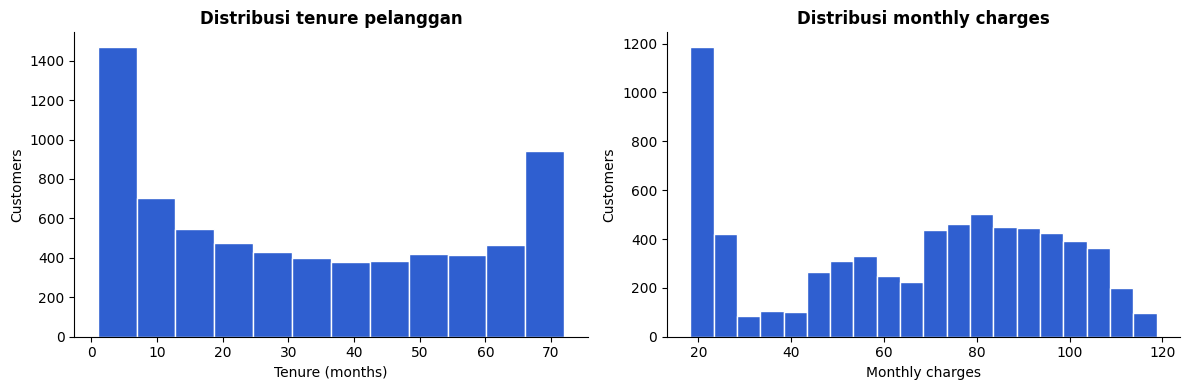

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    numeric_overview["tenure"].dropna(),
    bins=12,
    color=blue,
    edgecolor="white"
)
axes[0].set_title("Distribusi tenure pelanggan")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Customers")

axes[1].hist(
    numeric_overview["monthly_charges"],
    bins=20,
    color=blue,
    edgecolor="white"
)
axes[1].set_title("Distribusi monthly charges")
axes[1].set_xlabel("Monthly charges")
axes[1].set_ylabel("Customers")

plt.tight_layout()
plt.show()

In [39]:
fiber_segment_names = [
    "Fiber | 1–6 months",
    "Fiber | >6 months"
]

fiber_segments = df_analysis.loc[
    df_analysis["monthly_segment"].isin(fiber_segment_names)
].copy()

charges_summary = (
    fiber_segments
    .groupby(["monthly_segment", "customer_status"])
    .agg(
        customers=("customer_id", "size"),
        median_monthly_charges=("monthly_charges", "median"),
        mean_monthly_charges=("monthly_charges", "mean")
    )
)

display(charges_summary.round(2))

customers  median_monthly_charges  \
monthly_segment    customer_status                                      
Fiber | 1–6 months Churned                444                   79.45   
                   Joined                  86                   75.22   
                   Stayed                  43                   80.30   
Fiber | >6 months  Churned                663                   90.10   
                   Stayed                 646                   89.28   

                                    mean_monthly_charges  
monthly_segment    customer_status                        
Fiber | 1–6 months Churned                         80.85  
                   Joined                          79.28  
                   Stayed                          82.09  
Fiber | >6 months  Churned                         90.04  
                   Stayed                          89.07

#### Insight: Monthly Charges Belum Menjelaskan Perbedaan Churn

Pada segmen Fiber dengan tenure 1–6 bulan, median monthly charges pelanggan Churned sebesar 79,45, dibandingkan 80,30 pada Stayed.

Pada segmen Fiber dengan tenure lebih dari 6 bulan, median pelanggan Churned sebesar 90,10, dibandingkan sekitar 89,28 pada Stayed.

Median tagihan Churned dan Stayed relatif berdekatan dalam masing-masing segmen. Perbandingan ini belum menunjukkan dasar kuat untuk menjadikan besarnya tagihan sebagai penjelasan utama churn atau memberikan diskon secara menyeluruh.

Pelanggan tetap dapat menilai penawaran kompetitor lebih menarik meskipun tagihannya mirip dengan pelanggan yang bertahan. Evaluasi perlu mempertimbangkan manfaat layanan, perangkat, dan penawaran alternatif.

In [40]:
support_summary = (
    fiber_segments
    .groupby(["monthly_segment", "premium_tech_support"])
    .agg(
        customers=("customer_id", "size"),
        churners=("churn_flag", "sum")
    )
)

support_summary["churn_rate_pct"] = (
    support_summary["churners"]
    / support_summary["customers"] * 100
)

display(support_summary.round(2))

customers  churners  churn_rate_pct
monthly_segment    premium_tech_support                                     
Fiber | 1–6 months No                          524       411           78.44
                   Yes                          49        33           67.35
Fiber | >6 months  No                         1059       575           54.30
                   Yes                         250        88           35.20

#### Insight: Premium Tech Support Berkaitan dengan Churn yang Lebih Rendah

Pada segmen Fiber dengan tenure lebih dari 6 bulan:
- Tanpa Premium Tech Support: 575 churners dari 1.059 pelanggan, atau 54,30%.
- Dengan Premium Tech Support: 88 churners dari 250 pelanggan, atau 35,20%.

Pada segmen Fiber dengan tenure 1–6 bulan:
- Tanpa Premium Tech Support: 411 churners dari 524 pelanggan, atau 78,44%.
- Dengan Premium Tech Support: 33 churners dari 49 pelanggan, atau 67,35%.

Pengguna Premium Tech Support memiliki churn rate lebih rendah pada kedua segmen. Namun, jumlah pengguna support pada segmen tenure pendek hanya 49 pelanggan, sehingga hasilnya perlu dibaca dengan hati-hati.

Perbedaan ini belum membuktikan bahwa penambahan Premium Tech Support akan menurunkan churn. Karakteristik pelanggan dan pilihan paket dapat berbeda.

Kepemilikan Premium Tech Support juga tidak sama dengan kualitas interaksi support. Karena itu, hubungan ini dan alasan "Attitude of support person" digunakan sebagai dua petunjuk pemeriksaan yang berbeda.

### 8.7 Implications for Retention Evaluation

Dua segmen Fiber menunjukkan kebutuhan evaluasi yang berbeda:

- **Tenure 1–6 bulan:** memiliki churn rate teramati tertinggi, yaitu 77,49%. Evaluasi difokuskan pada pengalaman awal dan kesesuaian penawaran dengan kebutuhan pelanggan.
- **Tenure lebih dari 6 bulan:** memiliki volume churn lebih besar, yaitu 663 churners, serta 646 pelanggan aktif. Kelompok ini penting untuk evaluasi daya saing penawaran dan pengalaman layanan pelanggan yang sudah lebih lama berlangganan.

Alasan terkait kompetitor paling banyak tercatat pada kedua segmen. Perbandingan monthly charges belum mendukung diskon menyeluruh, sementara perbedaan churn menurut Premium Tech Support menjadi dasar untuk pemeriksaan lebih lanjut.

Temuan ini mendukung pengujian tindakan yang terarah. Efektivitasnya perlu dievaluasi melalui churn pada kelompok perlakuan dan pembanding selama periode pengamatan yang sama.

### 8.8 Satisfaction Score

Satisfaction Score diperiksa untuk menambahkan konteks pengalaman pelanggan pada segmen prioritas.

Distribusi skor dibandingkan menurut customer status terlebih dahulu, kemudian diperiksa pada pelanggan aktif di dua segmen Fiber.

Analisis menggunakan nilai skor yang tercatat tanpa menetapkan kategori puas atau tidak puas karena definisi skala dan waktu pengukurannya belum diverifikasi.

In [41]:
print("Score values:")
print(sorted(df_analysis["satisfaction_score"].dropna().unique()))

print(
    "Missing scores:",
    df_analysis["satisfaction_score"].isna().sum()
)

satisfaction_by_status = pd.crosstab(
    df_analysis["customer_status"],
    df_analysis["satisfaction_score"]
).reindex(
    index=["Churned", "Stayed", "Joined"],
    columns=[1, 2, 3, 4, 5],
    fill_value=0
)

display(satisfaction_by_status)

assert satisfaction_by_status.to_numpy().sum() == len(df_analysis)

Score values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Missing scores: 0


satisfaction_score,1,2,3,4,5
customer_status,,,,,
Churned,922,518,429,0,0
Stayed,0,0,2079,1637,1004
Joined,0,0,157,152,145


In [42]:
active_fiber_data = df_analysis.loc[
    df_analysis["monthly_segment"].isin([
        "Fiber | 1–6 months",
        "Fiber | >6 months"
    ])
    & df_analysis["customer_status"].isin(["Stayed", "Joined"])
].copy()

active_satisfaction_counts = pd.crosstab(
    [
        active_fiber_data["monthly_segment"],
        active_fiber_data["customer_status"]
    ],
    active_fiber_data["satisfaction_score"]
).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)

active_satisfaction_pct = (
    active_satisfaction_counts
    .div(active_satisfaction_counts.sum(axis=1), axis=0)
    * 100
)

print("Customer counts by score:")
display(active_satisfaction_counts)

print("Score distribution within each segment and status (%):")
display(active_satisfaction_pct.round(2))

assert active_satisfaction_counts.to_numpy().sum() == 775

Customer counts by score:


satisfaction_score                  1  2    3    4    5
monthly_segment    customer_status                     
Fiber | 1–6 months Joined           0  0   33   27   26
                   Stayed           0  0   20   14    9
Fiber | >6 months  Stayed           0  0  293  184  169

Score distribution within each segment and status (%):


satisfaction_score                    1    2      3      4      5
monthly_segment    customer_status                               
Fiber | 1–6 months Joined           0.0  0.0  38.37  31.40  30.23
                   Stayed           0.0  0.0  46.51  32.56  20.93
Fiber | >6 months  Stayed           0.0  0.0  45.36  28.48  26.16

#### Insight: Satisfaction Memberi Konteks, tetapi Belum Menentukan Prioritas

Pada seluruh dataset, skor 1–2 hanya ditemukan pada pelanggan Churned. Skor 4–5 hanya ditemukan pada Stayed dan Joined, sedangkan skor 3 muncul pada ketiga status.

Pola yang sangat terkait dengan status churn ini perlu ditinjau bersama dokumentasi waktu dan metode pengukuran. Pola tersebut sendiri tidak membuktikan bahwa skor dikumpulkan sebelum atau setelah churn.

Pada pelanggan aktif di dua segmen Fiber:
- Tenure 1–6 bulan, Stayed: 20 dari 43 pelanggan memiliki skor 3, atau 46,51%.
- Tenure 1–6 bulan, Joined: 33 dari 86 pelanggan memiliki skor 3, atau 38,37%.
- Tenure lebih dari 6 bulan, Stayed: 293 dari 646 pelanggan memiliki skor 3, atau 45,36%.

Seluruh pelanggan aktif memiliki skor 3–5. Persentase skor 3 pada pelanggan Stayed relatif mirip antarkedua segmen, sehingga hasil ini belum memberikan pembeda yang kuat untuk mengubah prioritas evaluasi.

Satisfaction digunakan sebagai konteks tambahan. Prioritas utama tetap berdasarkan churn aktual, volume churn, alasan churn, dan cakupan pelanggan aktif. Skor 3 tidak otomatis diartikan sebagai tidak puas atau berisiko churn.

### 8.9 Nilai Tagihan Pelanggan Churn

Jumlah pelanggan menunjukkan besarnya churn, tetapi belum menjelaskan nilai tagihan yang terkait dengan pelanggan tersebut.

Bagian ini membandingkan:
- Persentase pelanggan yang churn.
- Persentase tagihan bulanan yang berasal dari pelanggan churn.
- Kontribusi setiap segmen terhadap jumlah churners dan nilai tagihannya.

`monthly_charges` adalah nilai tagihan bulanan yang tercatat pada dataset. Penjumlahannya pada pelanggan Churned bukan estimasi kerugian pendapatan atau pendapatan yang pasti dapat diselamatkan.

In [43]:
# Ringkasan pelanggan dan tagihan berdasarkan status
billing_by_status = (
    df_analysis
    .groupby("customer_status")
    .agg(
        customers=("customer_id", "size"),
        total_monthly_charges=("monthly_charges", "sum"),
        avg_monthly_charges=("monthly_charges", "mean")
    )
    .reindex(["Churned", "Stayed", "Joined"])
)

billing_by_status["customer_share_pct"] = (
    billing_by_status["customers"] / len(df_analysis) * 100
)

billing_by_status["monthly_charges_share_pct"] = (
    billing_by_status["total_monthly_charges"]
    / df_analysis["monthly_charges"].sum()
    * 100
)

display(billing_by_status.round(2))

,customers,total_monthly_charges,avg_monthly_charges,customer_share_pct,monthly_charges_share_pct
customer_status,,,,,
Churned,1869,139130.85,74.44,26.54,30.50
Stayed,4720,297248.55,62.98,67.02,65.17
Joined,454,19737.20,43.47,6.45,4.33


#### Temuan Utama

Sebanyak 1.869 pelanggan berstatus Churned, atau 26,54% dari seluruh pelanggan.

Total tagihan bulanan yang tercatat untuk pelanggan tersebut adalah 139.130,85, setara dengan 30,50% dari seluruh tagihan bulanan dalam dataset.

Artinya, porsi nilai tagihan pelanggan churn lebih besar daripada porsi jumlah pelanggannya. Rata-rata tagihan bulanan Churned juga lebih tinggi, yaitu 74,44 dibandingkan 62,98 pada Stayed.

Temuan ini menjadi alasan untuk mempertimbangkan nilai tagihan saat membandingkan segmen, selain jumlah pelanggan dan churn rate.

In [44]:
# Ukuran pelanggan dan churn pada setiap segmen
segment_value_summary = (
    df_analysis
    .groupby("monthly_segment", observed=True)
    .agg(
        customers=("customer_id", "size"),
        churners=("churn_flag", "sum")
    )
)

segment_value_summary["active_customers"] = (
    segment_value_summary["customers"]
    - segment_value_summary["churners"]
)

segment_value_summary["churn_rate_pct"] = (
    segment_value_summary["churners"]
    / segment_value_summary["customers"]
    * 100
)

segment_value_summary["share_of_all_churners_pct"] = (
    segment_value_summary["churners"]
    / df_analysis["churn_flag"].sum()
    * 100
)

# Tagihan hanya dari pelanggan yang churn
churned_customers = df_analysis.loc[
    df_analysis["churn_flag"].eq(1)
]

charges_by_segment = (
    churned_customers
    .groupby("monthly_segment", observed=True)["monthly_charges"]
    .sum()
)

segment_value_summary["churned_monthly_charges"] = (
    charges_by_segment
    .reindex(segment_value_summary.index)
    .fillna(0)
)

segment_value_summary["share_of_churned_charges_pct"] = (
    segment_value_summary["churned_monthly_charges"]
    / churned_customers["monthly_charges"].sum()
    * 100
)

segment_value_summary = segment_value_summary.sort_values(
    "churned_monthly_charges",
    ascending=False
)

display(segment_value_summary.round(2))

,customers,churners,active_customers,churn_rate_pct,share_of_all_churners_pct,churned_monthly_charges,share_of_churned_charges_pct
monthly_segment,,,,,,,
Fiber | >6 months,1309,663,646,50.65,35.47,59695.85,42.91
Fiber | 1–6 months,573,444,129,77.49,23.76,35898.25,25.80
Other contracts,3433,214,3219,6.23,11.45,18283.75,13.14
Non-Fiber | 1–6 months,794,336,458,42.32,17.98,13783.05,9.91
Other monthly customers,934,212,722,22.70,11.34,11469.95,8.24


#### Nilai Tagihan Memperkuat Fokus pada Pelanggan Fiber

Di antara segmen yang dibandingkan:

- **Fiber dengan kontrak bulanan, tenure >6 bulan:** menyumbang 35,5% seluruh churners dan 42,9% tagihan churners. Kelompok ini memiliki 646 pelanggan aktif.
- **Fiber dengan kontrak bulanan, tenure 1–6 bulan:** memiliki churn rate tertinggi, yaitu 77,5%, serta menyumbang 25,8% tagihan churners. Kelompok ini memiliki 129 pelanggan aktif.
- **Non-Fiber dengan kontrak bulanan, tenure 1–6 bulan:** menyumbang 18,0% seluruh churners, tetapi 9,9% tagihan churners.

Kedua segmen Fiber bersama-sama menyumbang 59,23% seluruh churners dan 68,7% tagihan churners.

Dengan demikian, Fiber tenure >6 bulan menonjol dari sisi volume dan nilai tagihan, sedangkan Fiber tenure 1–6 bulan menonjol dari sisi churn rate. Keduanya perlu dipertimbangkan saat menentukan prioritas evaluasi retensi.

Persentase kontribusi menggunakan seluruh churners dalam dataset sebagai acuan, bukan hanya pelanggan kontrak bulanan.

### 8.10 Alasan Churn

Alasan churn diperiksa untuk mengetahui hal yang paling sering disebut pelanggan saat berhenti.

Persentase alasan dihitung dari seluruh pelanggan Churned. Analisis juga melihat nilai tagihan bulanan yang terkait dengan setiap kategori alasan.

Alasan yang tercatat menjadi petunjuk untuk evaluasi bisnis, tetapi belum membuktikan penyebab churn.

In [45]:
churned_customers = df_analysis.loc[
    df_analysis["churn_flag"].eq(1)
].copy()

total_churners = len(churned_customers)
total_churned_charges = churned_customers["monthly_charges"].sum()

reason_summary = (
    churned_customers
    .groupby("churn_category")
    .agg(
        churners=("customer_id", "size"),
        churned_monthly_charges=("monthly_charges", "sum")
    )
)

reason_summary["share_of_churners_pct"] = (
    reason_summary["churners"] / total_churners * 100
)

reason_summary["share_of_churned_charges_pct"] = (
    reason_summary["churned_monthly_charges"]
    / total_churned_charges * 100
)

print("Kategori alasan churn")
display(
    reason_summary.sort_values("churners", ascending=False).round(2)
)

top_reasons = (
    churned_customers["churn_reason"]
    .value_counts()
    .head(10)
    .rename_axis("churn_reason")
    .to_frame("churners")
)

top_reasons["share_of_churners_pct"] = (
    top_reasons["churners"] / total_churners * 100
)

print("Sepuluh alasan spesifik terbanyak")
display(top_reasons.round(2))

print("Persentase alasan di dalam setiap segmen")
segment_reason_pct = pd.crosstab(
    churned_customers["monthly_segment"],
    churned_customers["churn_category"],
    normalize="index"
) * 100

display(segment_reason_pct.round(2))

Kategori alasan churn


,churners,churned_monthly_charges,share_of_churners_pct,share_of_churned_charges_pct
churn_category,,,,
Competitor,841,64528.75,45.00,46.38
Attitude,314,22275.65,16.80,16.01
Dissatisfaction,303,22484.20,16.21,16.16
Price,211,14751.15,11.29,10.60
Other,200,15091.10,10.70,10.85


Sepuluh alasan spesifik terbanyak


,churners,share_of_churners_pct
churn_reason,,
Competitor had better devices,313,16.75
Competitor made better offer,311,16.64
Attitude of support person,220,11.77
Don't know,130,6.96
Competitor offered more data,117,6.26
Competitor offered higher download speeds,100,5.35
Attitude of service provider,94,5.03
Price too high,78,4.17
Product dissatisfaction,77,4.12


Persentase alasan di dalam setiap segmen


churn_category,Attitude,Competitor,Dissatisfaction,Other,Price
monthly_segment,,,,,
Fiber | 1–6 months,14.86,49.55,14.64,12.61,8.33
Fiber | >6 months,17.19,45.85,16.74,8.90,11.31
Non-Fiber | 1–6 months,19.05,39.88,17.26,8.63,15.18
Other contracts,14.02,43.46,16.82,12.15,13.55
Other monthly customers,18.87,42.45,15.57,14.15,8.96


#### Temuan Alasan Churn

Kompetitor menjadi kategori terbesar: 841 pelanggan atau 45,0% seluruh churners. Kelompok ini juga mencakup 46,4% tagihan bulanan pelanggan churn.

Dua alasan spesifik terbanyak adalah perangkat kompetitor yang lebih baik (313 pelanggan) dan penawaran kompetitor yang lebih baik (311 pelanggan).

Kategori Price mencakup 11,3% churners. Karena itu, harga bukan satu-satunya aspek yang perlu diperiksa; manfaat paket, perangkat, dan pengalaman layanan juga relevan.

Alasan churn membantu menentukan apa yang perlu dievaluasi. Jumlah pelanggan, churn rate, dan nilai tagihan membantu menentukan kelompok mana yang perlu diprioritaskan.

### 8.11 Layanan Tambahan dan Churn

Pelanggan dengan dan tanpa layanan tambahan dibandingkan untuk mencari pola churn.

Analisis hanya mencakup pelanggan internet agar pelanggan tanpa internet tidak tercampur dengan pelanggan yang memilih tidak menggunakan layanan tambahan.

Perbandingan dilakukan pada:
- Seluruh pelanggan internet.
- Pelanggan internet dengan kontrak bulanan, dipisahkan menurut tenure 1–6 bulan dan >6 bulan.

Pemisahan ini membantu melihat apakah pola tetap muncul pada kelompok kontrak dan tenure yang lebih sebanding. Perbandingan ini belum mengendalikan seluruh perbedaan karakteristik pelanggan.

In [46]:
service_columns = [
    "online_security",
    "online_backup",
    "device_protection",
    "premium_tech_support",
    "streaming_tv",
    "streaming_movies",
    "streaming_music",
    "unlimited_data"
]

def compare_services(data):
    rows = []

    for service in service_columns:
        yes = data.loc[data[service].eq("Yes")]
        no = data.loc[data[service].eq("No")]

        rows.append({
            "service": service,
            "customers_yes": len(yes),
            "churners_yes": yes["churn_flag"].sum(),
            "churn_rate_yes_pct": yes["churn_flag"].mean() * 100,
            "customers_no": len(no),
            "churners_no": no["churn_flag"].sum(),
            "churn_rate_no_pct": no["churn_flag"].mean() * 100
        })

    result = pd.DataFrame(rows).set_index("service")
    result["difference_pp"] = (
        result["churn_rate_yes_pct"]
        - result["churn_rate_no_pct"]
    )

    return result

internet_customers = df_analysis.loc[
    df_analysis["internet_service"].eq("Yes")
]

monthly_internet = internet_customers.loc[
    internet_customers["contract"].eq("Month-to-Month")
    & internet_customers["tenure"].gt(0)
]

service_groups = {
    "Seluruh pelanggan internet": internet_customers,
    "Kontrak bulanan, tenure 1–6 bulan": monthly_internet.loc[
        monthly_internet["tenure"].between(1, 6)
    ],
    "Kontrak bulanan, tenure >6 bulan": monthly_internet.loc[
        monthly_internet["tenure"].gt(6)
    ]
}

for group_name, group_data in service_groups.items():
    print(f"\n{group_name}: {len(group_data):,} pelanggan")
    display(compare_services(group_data).round(2))


Seluruh pelanggan internet: 5,517 pelanggan


,customers_yes,churners_yes,churn_rate_yes_pct,customers_no,churners_no,churn_rate_no_pct,difference_pp
service,,,,,,,
online_security,2019,295,14.61,3498,1461,41.77,-27.16
online_backup,2429,523,21.53,3088,1233,39.93,-18.40
device_protection,2422,545,22.50,3095,1211,39.13,-16.63
premium_tech_support,2044,310,15.17,3473,1446,41.64,-26.47
streaming_tv,2707,814,30.07,2810,942,33.52,-3.45
streaming_movies,2732,818,29.94,2785,938,33.68,-3.74
streaming_music,2488,728,29.26,3029,1028,33.94,-4.68
unlimited_data,4745,1502,31.65,772,254,32.90,-1.25



Kontrak bulanan, tenure 1–6 bulan: 1,072 pelanggan


,customers_yes,churners_yes,churn_rate_yes_pct,customers_no,churners_no,churn_rate_no_pct,difference_pp
service,,,,,,,
online_security,134,55,41.04,938,649,69.19,-28.14
online_backup,199,117,58.79,873,587,67.24,-8.45
device_protection,161,115,71.43,911,589,64.65,6.77
premium_tech_support,145,69,47.59,927,635,68.50,-20.91
streaming_tv,269,196,72.86,803,508,63.26,9.60
streaming_movies,268,195,72.76,804,509,63.31,9.45
streaming_music,303,223,73.60,769,481,62.55,11.05
unlimited_data,927,618,66.67,145,86,59.31,7.36



Kontrak bulanan, tenure >6 bulan: 2,020 pelanggan


,customers_yes,churners_yes,churn_rate_yes_pct,customers_no,churners_no,churn_rate_no_pct,difference_pp
service,,,,,,,
online_security,528,158,29.92,1492,694,46.51,-16.59
online_backup,762,288,37.80,1258,564,44.83,-7.04
device_protection,704,302,42.90,1316,550,41.79,1.10
premium_tech_support,480,137,28.54,1540,715,46.43,-17.89
streaming_tv,918,461,50.22,1102,391,35.48,14.74
streaming_movies,916,461,50.33,1104,391,35.42,14.91
streaming_music,822,362,44.04,1198,490,40.90,3.14
unlimited_data,1718,715,41.62,302,137,45.36,-3.75


#### Temuan Layanan Tambahan

Online Security dan Premium Tech Support berkaitan dengan churn rate yang lebih rendah, baik pada seluruh pelanggan internet maupun setelah dipisahkan menurut kontrak bulanan dan kelompok tenure.

Online Backup menunjukkan perbedaan yang lebih kecil. Pola Device Protection dan streaming berubah ketika pelanggan dibandingkan dalam kelompok yang lebih spesifik.

Karena itu, kepemilikan layanan tidak langsung dianggap sebagai penyebab churn yang lebih rendah. Pelanggan yang memilih layanan tertentu mungkin juga memiliki karakteristik berbeda.

Analisis berikutnya berfokus pada kombinasi Online Security dan Premium Tech Support di kelompok Fiber dengan kontrak bulanan.

In [47]:
# Kelompok layanan berlaku untuk seluruh pelanggan internet
has_internet = df_analysis["internet_service"].eq("Yes")

no_security_support = (
    df_analysis["online_security"].eq("No")
    & df_analysis["premium_tech_support"].eq("No")
)

df_analysis["security_support_group"] = "No Internet"

df_analysis.loc[
    has_internet, "security_support_group"
] = "Has Security and/or Tech Support"

df_analysis.loc[
    has_internet & no_security_support,
    "security_support_group"
] = "No Security and no Tech Support"

# Penanda kelompok fokus; bukan prediksi churn individu
df_analysis["fiber_monthly_no_support_flag"] = (
    df_analysis["contract"].eq("Month-to-Month")
    & df_analysis["internet_type"].eq("Fiber Optic")
    & df_analysis["tenure"].gt(0)
    & no_security_support
).astype(int)

fiber_monthly = df_analysis.loc[
    df_analysis["contract"].eq("Month-to-Month")
    & df_analysis["internet_type"].eq("Fiber Optic")
    & df_analysis["tenure"].gt(0)
].copy()

combo_summary = (
    fiber_monthly
    .groupby("security_support_group")
    .agg(
        customers=("customer_id", "size"),
        churners=("churn_flag", "sum")
    )
)

combo_summary["active_customers"] = (
    combo_summary["customers"] - combo_summary["churners"]
)

combo_summary["churn_rate_pct"] = (
    combo_summary["churners"] / combo_summary["customers"] * 100
)

combo_summary["share_of_all_churners_pct"] = (
    combo_summary["churners"] / total_churners * 100
)

combo_charges = (
    fiber_monthly.loc[fiber_monthly["churn_flag"].eq(1)]
    .groupby("security_support_group")["monthly_charges"]
    .sum()
)

combo_summary["churned_monthly_charges"] = (
    combo_charges.reindex(combo_summary.index).fillna(0)
)

combo_summary["share_of_churned_charges_pct"] = (
    combo_summary["churned_monthly_charges"]
    / total_churned_charges * 100
)

display(combo_summary.round(2))

,customers,churners,active_customers,churn_rate_pct,share_of_all_churners_pct,churned_monthly_charges,share_of_churned_charges_pct
security_support_group,,,,,,,
Has Security and/or Tech Support,539,224,315,41.56,11.99,20932.9,15.05
No Security and no Tech Support,1343,883,460,65.75,47.24,74661.2,53.66


In [48]:
combo_by_tenure = (
    fiber_monthly
    .groupby(
        ["monthly_segment", "security_support_group"],
        observed=True
    )
    .agg(
        customers=("customer_id", "size"),
        churners=("churn_flag", "sum")
    )
)

combo_by_tenure["active_customers"] = (
    combo_by_tenure["customers"] - combo_by_tenure["churners"]
)

combo_by_tenure["churn_rate_pct"] = (
    combo_by_tenure["churners"]
    / combo_by_tenure["customers"] * 100
)

display(combo_by_tenure.round(2))

customers  churners  \
monthly_segment    security_support_group                                  
Fiber | 1–6 months Has Security and/or Tech Support         80        47   
                   No Security and no Tech Support         493       397   
Fiber | >6 months  Has Security and/or Tech Support        459       177   
                   No Security and no Tech Support         850       486   

                                                     active_customers  \
monthly_segment    security_support_group                               
Fiber | 1–6 months Has Security and/or Tech Support                33   
                   No Security and no Tech Support                 96   
Fiber | >6 months  Has Security and/or Tech Support               282   
                   No Security and no Tech Support                364   

                                                     churn_rate_pct  
monthly_segment    security_support_group                            
Fiber | 1–6 months Has Security and/or Tech Support           58.75  
                   No Security and no Tech Support            80.53  
Fiber | >6 months  Has Security and/or Tech Support           38.56  
                   No Security and no Tech Support            57.18

In [52]:
# Memeriksa kombinasi layanan pada masing-masing kelompok tenure
combo_by_tenure = (
    fiber_monthly
    .groupby(
        ["monthly_segment", "security_support_group"],
        observed=True
    )
    .agg(
        customers=("customer_id", "size"),
        churners=("churn_flag", "sum")
    )
)

combo_by_tenure["churn_rate_pct"] = (
    combo_by_tenure["churners"]
    / combo_by_tenure["customers"] * 100
)

combo_by_tenure["active_customers"] = (
    combo_by_tenure["customers"]
    - combo_by_tenure["churners"]
)

display(combo_by_tenure.round(2))

customers  churners  \
monthly_segment    security_support_group                                  
Fiber | 1–6 months Has Security and/or Tech Support         80        47   
                   No Security and no Tech Support         493       397   
Fiber | >6 months  Has Security and/or Tech Support        459       177   
                   No Security and no Tech Support         850       486   

                                                     churn_rate_pct  \
monthly_segment    security_support_group                             
Fiber | 1–6 months Has Security and/or Tech Support           58.75   
                   No Security and no Tech Support            80.53   
Fiber | >6 months  Has Security and/or Tech Support           38.56   
                   No Security and no Tech Support            57.18   

                                                     active_customers  
monthly_segment    security_support_group                              
Fiber | 1–6 months Has Security and/or Tech Support                33  
                   No Security and no Tech Support                 96  
Fiber | >6 months  Has Security and/or Tech Support               282  
                   No Security and no Tech Support                364

#### Konsentrasi Churn pada Pelanggan Tanpa Security dan Tech Support

Di antara pelanggan Fiber dengan kontrak bulanan:

- Tanpa kedua layanan: 883 dari 1.343 pelanggan churn, atau 65,7%.
- Memiliki minimal satu layanan: 224 dari 539 pelanggan churn, atau 41,6%.

Kelompok tanpa kedua layanan menyumbang 47,2% seluruh churners dan 53,7% tagihan bulanan seluruh churners.

Perbedaan tetap terlihat setelah dipisahkan menurut tenure:
- Tenure 1–6 bulan: 80,5% tanpa kedua layanan dibanding 58,8% dengan minimal satu layanan.
- Tenure >6 bulan: 57,2% dibanding 38,6%.

Kelompok tanpa kedua layanan memiliki 460 pelanggan aktif: 96 dengan tenure 1–6 bulan dan 364 dengan tenure >6 bulan.

Sebanyak 460 pelanggan tersebut merupakan bagian dari 775 pelanggan aktif Fiber kontrak bulanan, bukan kelompok tambahan yang dapat dijumlahkan.

Pola ini mendukung evaluasi kebutuhan layanan dan pengalaman pelanggan. Namun, hasilnya belum membuktikan bahwa menambahkan Security atau Tech Support akan menurunkan churn.

### 8.12 CLTV sebagai Konteks Nilai Pelanggan

CLTV digunakan untuk memahami nilai relatif pelanggan, termasuk pelanggan aktif dalam segmen prioritas.

Analisis menggunakan CLTV yang sudah tersedia dalam dataset. Formula rinci, satuan, dan waktu pembentukan nilainya belum terverifikasi untuk versi data ini. Karena itu, CLTV tidak dianggap sebagai pendapatan atau keuntungan yang pasti diperoleh.

Pelanggan dibagi menjadi empat kelompok berdasarkan CLTV seluruh dataset:
- Q1: sekitar 25% pelanggan dengan CLTV terendah.
- Q2 dan Q3: kelompok tengah.
- Q4: sekitar 25% pelanggan dengan CLTV tertinggi.

Batas kelompok dibuat dari seluruh dataset dan tetap digunakan saat membandingkan segmen.

In [49]:
df_analysis["cltv_band"] = pd.qcut(
    df_analysis["cltv"],
    q=4,
    labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]
)

df_analysis["cltv_band_order"] = (
    df_analysis["cltv_band"].cat.codes + 1
)

print("CLTV berdasarkan status")
display(
    df_analysis.groupby("customer_status")
    .agg(
        customers=("customer_id", "size"),
        median_cltv=("cltv", "median")
    )
    .reindex(["Churned", "Stayed", "Joined"])
    .round(2)
)

cltv_summary = (
    df_analysis
    .groupby("cltv_band", observed=True)
    .agg(
        customers=("customer_id", "size"),
        churners=("churn_flag", "sum"),
        cltv_min=("cltv", "min"),
        cltv_max=("cltv", "max"),
        median_tenure=("tenure", "median")
    )
)

cltv_summary["churn_rate_pct"] = (
    cltv_summary["churners"] / cltv_summary["customers"] * 100
)

print("CLTV dan churn pada seluruh pelanggan")
display(cltv_summary.round(2))

contract_cltv = (
    df_analysis
    .groupby(["contract", "cltv_band"], observed=True)
    .agg(
        customers=("customer_id", "size"),
        churners=("churn_flag", "sum")
    )
)

contract_cltv["churn_rate_pct"] = (
    contract_cltv["churners"] / contract_cltv["customers"] * 100
)

print("CLTV dan churn di dalam jenis kontrak yang sama")
display(contract_cltv.round(2))

CLTV berdasarkan status


,customers,median_cltv
customer_status,,
Churned,1869,4238.0
Stayed,4720,4666.0
Joined,454,4132.0


CLTV dan churn pada seluruh pelanggan


,customers,churners,cltv_min,cltv_max,median_tenure,churn_rate_pct
cltv_band,,,,,,
Q1 (lowest),1763,607,2003,3469,15.0,34.43
Q2,1759,472,3470,4527,26.0,26.83
Q3,1760,425,4528,5380,39.0,24.15
Q4 (highest),1761,365,5381,6500,51.0,20.73


CLTV dan churn di dalam jenis kontrak yang sama


customers  churners  churn_rate_pct
contract       cltv_band                                        
Month-to-Month Q1 (lowest)        1199       568           47.37
               Q2                  916       424           46.29
               Q3                  792       367           46.34
               Q4 (highest)        703       296           42.11
One Year       Q1 (lowest)         328        36           10.98
               Q2                  392        41           10.46
               Q3                  423        41            9.69
               Q4 (highest)        407        48           11.79
Two Year       Q1 (lowest)         236         3            1.27
               Q2                  451         7            1.55
               Q3                  545        17            3.12
               Q4 (highest)        651        21            3.23

In [50]:
active_mask = df_analysis["customer_status"].isin(["Stayed", "Joined"])
top_cltv_mask = df_analysis["cltv_band"].eq("Q4 (highest)")

priority_masks = {
    "Fiber monthly | >6 months":
        df_analysis["monthly_segment"].eq("Fiber | >6 months"),

    "Fiber monthly | 1–6 months":
        df_analysis["monthly_segment"].eq("Fiber | 1–6 months"),

    "Fiber monthly | no Security and no Tech Support":
        df_analysis["fiber_monthly_no_support_flag"].eq(1)
}

cltv_rows = []

for segment_name, segment_mask in priority_masks.items():
    customers = df_analysis.loc[segment_mask & active_mask]
    high_cltv_count = customers["cltv_band"].eq("Q4 (highest)").sum()

    cltv_rows.append({
        "segment": segment_name,
        "active_customers": len(customers),
        "median_cltv_active": customers["cltv"].median(),
        "active_high_cltv_customers": high_cltv_count,
        "active_high_cltv_pct": (
            high_cltv_count / len(customers) * 100
            if len(customers) else float("nan")
        )
    })

priority_cltv = pd.DataFrame(cltv_rows).set_index("segment")
display(priority_cltv.round(2))

print(
    "Porsi Q4 di antara seluruh pelanggan aktif:",
    f"{top_cltv_mask.loc[active_mask].mean():.2%}"
)

,active_customers,median_cltv_active,active_high_cltv_customers,active_high_cltv_pct
segment,,,,
Fiber monthly | >6 months,646,4512.5,144,22.29
Fiber monthly | 1–6 months,129,3956.0,21,16.28
Fiber monthly | no Security and no Tech Support,460,4276.5,95,20.65


Porsi Q4 di antara seluruh pelanggan aktif: 26.98%


#### Peran CLTV dalam Prioritas

Median CLTV pelanggan Churned adalah 4.238, lebih rendah daripada Stayed sebesar 4.666.

Pada seluruh pelanggan, churn rate turun dari 34,4% pada Q1 menjadi 20,7% pada Q4. Namun, median tenure juga meningkat dari 15 menjadi 51 bulan.

Di dalam kontrak bulanan, perbedaan churn rate mengecil menjadi 47,4% pada Q1 dan 42,1% pada Q4. Ini menunjukkan bahwa pola CLTV secara keseluruhan perlu dibaca bersama karakteristik kontrak dan tenure.

CLTV digunakan untuk memperinci nilai pelanggan aktif, bukan sebagai prediksi churn:
- Fiber bulanan >6 bulan: 144 dari 646 pelanggan aktif berada di Q4.
- Fiber bulanan 1–6 bulan: 21 dari 129 pelanggan aktif berada di Q4.
- Fiber bulanan tanpa Security maupun Tech Support: 95 dari 460 pelanggan aktif berada di Q4.

Kelompok terakhir beririsan dengan dua kelompok sebelumnya.

Porsi pelanggan Q4 pada segmen tersebut lebih rendah daripada porsi Q4 pada seluruh pelanggan aktif, yaitu sekitar 27,0%. Jadi, segmen prioritas tidak otomatis berisi pelanggan dengan CLTV tertinggi.

Prioritas tetap didasarkan pada konsentrasi churn, nilai tagihan, dan pola layanan. CLTV menjadi informasi tambahan untuk evaluasi pelanggan aktif di dalam segmen tersebut.

## 9. Key Findings

### Ukuran Masalah dan Nilai Tagihan

Sebanyak 1.869 dari 7.043 pelanggan berstatus Churned, atau 26,54%.

Pelanggan churn terkait dengan 139.130,85 tagihan bulanan, setara dengan 30,50% seluruh tagihan bulanan dalam dataset. Nilai ini bukan estimasi kerugian pendapatan.

### Alasan Berhenti yang Paling Sering Tercatat

Kompetitor menjadi kategori alasan terbesar, mencakup 45,0% churners. Perangkat dan penawaran kompetitor menjadi dua alasan spesifik terbanyak.

Temuan ini mendukung evaluasi daya saing manfaat paket dan perangkat, bukan langsung menyimpulkan perlunya diskon menyeluruh.

### Konsentrasi pada Kontrak Bulanan dan Fiber

Kontrak bulanan menyumbang 88,55% seluruh churners.

Dua kelompok Fiber kontrak bulanan menyumbang 59,23% churners dan 68,7% tagihan churners:
- Tenure >6 bulan menonjol dari sisi jumlah churners dan nilai tagihan.
- Tenure 1–6 bulan memiliki churn rate tertinggi di antara kelompok yang dibandingkan.

### Pola Layanan Memperinci Kelompok Prioritas

Pelanggan Fiber kontrak bulanan tanpa Security maupun Tech Support menyumbang 47,2% seluruh churners dan 53,7% tagihan churners.

Churn rate kelompok ini lebih tinggi daripada pelanggan yang memiliki minimal satu layanan, termasuk setelah dipisahkan menurut kelompok tenure.

### Pelanggan Aktif untuk Evaluasi Lebih Lanjut

Terdapat 775 pelanggan aktif Fiber kontrak bulanan. Di dalamnya, 460 tidak memiliki Security maupun Tech Support, dan 95 dari 460 pelanggan tersebut berada di kuartil CLTV tertinggi.

Angka ini menunjukkan kelompok yang dapat dievaluasi lebih lanjut, bukan pelanggan yang dipastikan akan churn.

## 10. Business Recommendations

### 1. Prioritaskan Evaluasi Pelanggan Fiber dengan Kontrak Bulanan

Dasar: dua kelompok Fiber menyumbang 68,7% tagihan churners. Kelompok tenure >6 bulan memiliki volume dan nilai tagihan lebih besar, sementara tenure 1–6 bulan memiliki churn rate lebih tinggi.

Gunakan jumlah pelanggan, churn rate, dan kontribusi tagihan secara bersamaan saat menentukan prioritas. Di dalam kelompok aktif, CLTV dapat menjadi pertimbangan nilai tambahan.

### 2. Evaluasi Daya Saing Paket dan Perangkat

Dasar: kompetitor menjadi alasan berhenti yang paling sering tercatat, terutama terkait perangkat dan penawaran.

Periksa apakah manfaat paket dan perangkat sesuai dengan kebutuhan pelanggan prioritas. Data saat ini belum cukup untuk menentukan bentuk penawaran atau besarnya diskon.

### 3. Evaluasi Kebutuhan Security dan Pengalaman Tech Support

Dasar: churn terkonsentrasi pada pelanggan Fiber kontrak bulanan tanpa kedua layanan tersebut. Pola tetap terlihat pada dua kelompok tenure.

Periksa kebutuhan, pemahaman manfaat layanan, serta kendala pelanggan. Jangan langsung menganggap penjualan layanan tambahan sebagai solusi yang sudah terbukti.

### Metric untuk Evaluasi Berikutnya

Jika rekomendasi diuji melalui program, ukur:
- Churn rate kelompok program dan kelompok pembanding dengan masa pengamatan yang sama.
- Biaya program dan nilai pendapatan yang benar-benar dipertahankan selama periode evaluasi.
- Penyelesaian keluhan dan kepuasan setelah layanan sebagai metric pendukung.

Metric evaluasi tersebut membutuhkan data lanjutan. Hasilnya belum dapat dihitung dari snapshot ini.

## 11. Batas Analisis

- Dataset menggambarkan satu snapshot Q3, sehingga tidak digunakan untuk menyimpulkan tren atau retention antarperiode.
- Churn rate adalah proporsi pelanggan berstatus Churned di dalam kelompok pada dataset.
- Total tagihan bulanan churners bukan estimasi kerugian atau keuntungan program retensi.
- Hubungan kontrak, tenure, dan layanan dengan churn tidak membuktikan sebab-akibat.
- Alasan churn hanya tersedia untuk pelanggan yang sudah berhenti dan digunakan sebagai petunjuk evaluasi.
- Waktu pengukuran Satisfaction Score serta pembentukan CLTV dan Churn Score belum terverifikasi untuk versi dataset ini.
- Pelanggan aktif pada segmen prioritas bukan hasil prediksi churn individu.
- Sebanyak 11 pelanggan dengan tenure 0 tetap dipertahankan dan ditandai untuk pemeriksaan.
- Segmen berdasarkan kombinasi layanan beririsan dengan segmen tenure sehingga tidak boleh dijumlahkan langsung.

## 12. Validasi dan Ekspor Data

Pemeriksaan akhir memastikan jumlah pelanggan, jumlah churners, dan kelompok prioritas sesuai dengan hasil analisis.

Data diekspor ke `telco_churn_powerbi.csv` dengan satu baris per pelanggan. File ini mencakup kolom kombinasi layanan dan kelompok CLTV untuk digunakan di Power BI.

In [51]:
from google.colab import files

# 1. Validasi data pelanggan
assert len(df_analysis) == 7043
assert df_analysis["customer_id"].notna().all()
assert df_analysis["customer_id"].is_unique
assert df_analysis["churn_flag"].isin([0, 1]).all()
assert df_analysis["churn_flag"].sum() == 1869
assert df_analysis["monthly_segment"].notna().all()

# 2. Pastikan kolom tambahan sudah tersedia dan tidak kosong
new_columns = [
    "security_support_group",
    "fiber_monthly_no_support_flag",
    "cltv_band",
    "cltv_band_order"
]

assert all(column in df_analysis.columns for column in new_columns), (
    "Jalankan cell kombinasi layanan dan CLTV sebelum ekspor."
)
assert df_analysis[new_columns].notna().all().all()

# 3. Tentukan pelanggan aktif dan kelompok CLTV tertinggi
active_mask = df_analysis["customer_status"].isin(["Stayed", "Joined"])
high_cltv_mask = df_analysis["cltv_band"].eq("Q4 (highest)")

# 4. Validasi dua segmen Fiber kontrak bulanan
fiber_mask = df_analysis["monthly_segment"].isin([
    "Fiber | 1–6 months",
    "Fiber | >6 months"
])

assert fiber_mask.sum() == 1882
assert df_analysis.loc[fiber_mask, "churn_flag"].sum() == 1107
assert (fiber_mask & active_mask).sum() == 775

# 5. Validasi Fiber bulanan tanpa Security maupun Tech Support
focus_mask = df_analysis["fiber_monthly_no_support_flag"].eq(1)

assert focus_mask.sum() == 1343
assert df_analysis.loc[focus_mask, "churn_flag"].sum() == 883
assert (focus_mask & active_mask).sum() == 460
assert (focus_mask & active_mask & high_cltv_mask).sum() == 95

# 6. Ekspor data untuk Power BI
filename = "telco_churn_powerbi.csv"

df_analysis.to_csv(
    filename,
    index=False,
    encoding="utf-8-sig"
)

print("Validasi berhasil.")
print(f"Jumlah pelanggan: {len(df_analysis):,}")
print(f"Jumlah churners: {df_analysis['churn_flag'].sum():,}")
print(f"Jumlah kolom: {df_analysis.shape[1]}")
print(f"File siap digunakan: {filename}")

files.download(filename)

Validasi berhasil.
Jumlah pelanggan: 7,043
Jumlah churners: 1,869
Jumlah kolom: 61
File siap digunakan: telco_churn_powerbi.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>